# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

In [3]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

In [4]:
import json

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

# TODO:
1. Wikipedia harvest - Run as is for now, try to understand why it crushes near the end. **---------> DONE!**
2. Extract tables:
    - length between 3 to 10 **---------> DONE!**
    - table is square and parsed normally (no merged cells) **---------> DONE!**
    - full table **---------> DONE!**
    - remove some columns with no relevant data (empty or by keywords) **---------> DONE!**
3. Add to table extraction text titles and relevant paragraphs for the context. **---------> DONE!**
4. Cluster titles to remove similar options + take only one table per page. **---------> DONE!**
5. Create groups - all the table, try to see what is the main entity - return the column name, if they don't have one, discard the table and return 'None'. **---------> DONE!**
6. Create Questions
    - strategy injection, sample a subset of strategies in a shuffled order, if not possible than discard table.
    - make a function to extract the answer per question strategy --> create GT answer.
    - Add the 'group size' strategy.
    - constract the data samples.

### Havest Wikipedia pages with tables:

In [91]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiHarvester
# Initialize Wikipedia harvester
harvester = WikiHarvester()
# Run Phase 1 - Harvesting titles based on keywords
harvester.run_complete_harvest()
# Run Phase 2 - Filtering pages for tables
await harvester.filter_pages_async()

Harvesting Pages By Keywords:   0%|          | 0/233 [00:00<?, ?keyword/s]


TOTAL UNIQUE TITLES COLLECTED: 167913



Method,Keyword,Count
Prefix,List of cities,1537
Prefix,List of countries,1278
Prefix,List of towns,501
Prefix,List of villages,483
Prefix,List of districts,375
Prefix,List of municipalities,1021
Prefix,List of communes,194
Prefix,List of counties,259
Prefix,List of provinces,84
Prefix,List of territories,22


Filtering Pages with Tables:   0%|          | 0/167913 [00:00<?, ?page/s]


TOTAL PAGES WITH TABLES COLLECTED: 62306



In [93]:
save_json("table_titles", harvester.valid_titles)

In [3]:
table_titles = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/table_titles.json")

### Parse and filter Wikipedia tables:

In [271]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

Pre-processing: cluster similar pages and discard similarities ---> 6426 pages discarded.


Extracting Tables:   0%|          | 0/55880 [00:00<?, ?Page/s]

Starting Extraction: 55880 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 32076 OUT OF 55880 (57.4%)


Filtering & Cleaning:   0%|          | 0/94101 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      94101
Dropped (Bad Headers):     8435
Dropped (Cell too long):   2841
Dropped (Repeat Rows):     1783
Short tables found:        39837
Unique source pages:       16940
Final sampled (1/page):    16940
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------

══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Rank,Player,Career,Caps,Goals
0,1,Christine Sinclair,2000–2023,331,190
1,2,Sophie Schmidt,2005–2023,226,20
2,3,Diana Matheson,2003–2021,206,19
3,4,Desiree Scott,2010–2025,188,0
4,5,Rhian Wilkinson,2003–2017,181,7
5,6,Kadeisha Buchanan,2013–present,154,6
6,7,Ashley Lawrence,2013–present,151,8
7,7,Jessie Fleming,2013–present,151,20
8,9,Brittany Baxter,2002–2014,132,5
9,9,Andrea Neil,1991–2007,132,24



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Manchester City F.C. 3–2 Queens Park Rangers F.C. > Match > Statistics
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Statistic,Manchester City,Queens Park Rangers
0,Goals scored,3,2
1,Possession,81.3%,18.7%
2,Shots on target,15,3
3,Shots off target,10,0
4,Blocked shots,19,0
5,Corner kicks,19,0
6,Fouls,4,7
7,Tackles,15,22
8,Offsides,1,1
9,Yellow cards,2,1



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Swinburne University of Technology > Notable people > Academics and staff
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Member,Executive team,Period
0,Pascale Quester,Vice-Chancellor,2020–present
1,Chris Pilgrim,Pro Vice-Chancellor (Academic),
2,Tara Magdalinski,Pro Vice-Chancellor (Education and Quality),
3,Sarah Maddison,Pro Vice-Chancellor (Academic Innovation and C...,
4,Bronwyn Fox,Deputy Vice-Chancellor (Research and Enterprise),
5,Beth Webster,Pro Vice-Chancellor (Research Policy and Impact),
6,Qing-Lon Han,Pro Vice-Chancellor (Research Quality),
7,Alan Kin-Tak Lau,Pro Vice-Chancellor (International Research De...,
8,Blair Kuys,Dean of the School of Design and Architecture,
9,Matthew Bailes,Director of the Data Science Research Institut...,


### Create Potential Entity Groups:

In [243]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 1000))
await group_constructor.get_groups()

🚀 Grouping 1000 tables using Entity-Focus logic...


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/1000 [00:00<?, ?it/s]


════════════════════════════════════════════════════════════════════════════════
                               📊 GROUPING REPORT                                
════════════════════════════════════════════════════════════════════════════════
  ✅ Valid Groups:   860
  ❌ Invalid Tables: 140
════════════════════════════════════════════════════════════════════════════════

✨ SAMPLE VALID NAMES:
  → Achievements of Zhang Hao in Triple Jump
  → Players in the 2006 Players Championship First Round
  → THE subject rankings of the University of Hong Kong

────────────────────────────────────────────────────────────────────────────────
                     🕵️ REJECTION DEBUGGER (Random Sample)                      
────────────────────────────────────────────────────────────────────────────────

[TABLE]: League of Ireland Player of the Month > Awards won by nationality (As of 11 November 2025)
[REASON]: The table contains generic categories (countries) and is a summary of wins by nationality, 

In [156]:
for sample in random.sample(group_constructor.valid_tables, 25):
    print(f"Group name: {sample['Group name']}")
    print(f"Wikipedia page: {sample['Wikipedia link']}")
    print(f"Entity column: {sample['Entity column']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Architectural Resources in Phases I and II of the University–Cultural Center Area
Wikipedia page: https://en.wikipedia.org/wiki/University–Cultural_Center_Multiple_Resource_Area#Architecture
Entity column: Resource name


,Resource name,Address,Built,Architect,Phase,Note
0,Cass Motor Sales,5800 Cass Avenue,1928,Unknown,Phase I,
1,Samuel L. Smith House,5035 Woodward Avenue,1889,Rogers and MacFarlane,Phase I,
2,Thomas S. Sprague House,80 West Palmer Street,1884,William Scott & Co,Phase I,This structure has been demolished.
3,Herman Strasburg House,5415 Cass Avenue,1915,Marcus Burrowes,Phase I,
4,Verona Apartments,92 West Ferry Street,1894,"William G. Malcomson, William E. Higginbotham",Phase I,
5,Chatsworth Apartments,630 Merrick Street (now on Wayne State Univers...,1927,"Pollmar, Ropes & Lundy",Phase II,
6,Saint Andrew's Memorial Episcopal Church,5105 Anthony Wayne Drive (now on Wayne State U...,1894,"Cram, Wentworth & Goodhue",Phase II,
7,Santa Fe Apartments,681 Merrick Street (now on Wayne State Univers...,1925,"F. W. Wiedmaier, John B. Gay",Phase II,This structure has been demolished.




Group name: Titles held by professional shogi players
Wikipedia page: https://en.wikipedia.org/wiki/Professional_shogi_player#Tournaments
Entity column: Title name


,Title name,Japanese name,Titleholder
0,Eiō,叡王,Takumi Itō
1,Kiō,棋王,Sōta Fujii
2,Kisei,棋聖,Sōta Fujii
3,Meijin,名人,Sōta Fujii
4,Ōi,王位,Sōta Fujii
5,Ōshō,王将,Sōta Fujii
6,Ōza,王座,Takumi Itō
7,Ryūō,竜王,Sōta Fujii




Group name: Awards and nominations received by NYPD Blue for Artios Awards
Wikipedia page: https://en.wikipedia.org/wiki/List_of_awards_and_nominations_received_by_NYPD_Blue#Awards_and_nominations
Entity column: Nominee(s)


...

,Award,Film,Language,Awardee(s),Cash prize
0,Best Information Film (Documentary),Everest,English,Producer: Arun Chowdhury for Films Division,"₹ 5,000 and a medal"
1,Best Information Film (Documentary),Everest,English,Director: N. S. Thapa,"₹ 2,000 and a plaque"
2,Best Educational / Instructional Film,Forest and The Man,English,Producer: K. L. Khandpur for Films Division,"₹ 5,000 and a medal"
3,Best Educational / Instructional Film,Forest and The Man,English,Director: Neil Gokhale,"₹ 2,000 and a plaque"
4,Best Educational / Instructional Film,Forest and The Man,English,Director: P. B. Pendharkar,"₹ 2,000 and a plaque"
5,Best Film on Social Documentation,Water,English,Producer: M/s. Fali Billmoria Productions,"₹ 5,000 and a medal"
6,Best Film on Social Documentation,Water,English,Director: Fali Billmoria,"₹ 2,000 and a plaque"
7,Best Experimental Film,And I Make Short Films,English,Producer: K. L. Khandpur for Films Division,"₹ 5,000 and a medal"
8,Best Experimental Film,And I Make Short Films,English,Director: S. N. S. Sastry,"₹ 2,000 and a plaque"
9,Best Animation Film,Nag Aur Kauwa,Hindi,Producer: Children's Film Society,"₹ 5,000 and a medal"




Group name: R. Norris Williams' Grand Slam Doubles Finals Results
Wikipedia page: https://en.wikipedia.org/wiki/R._Norris_Williams#Grand_Slam_finals
Entity column: Championship


,Result,Year,Championship,Surface,Partner,Opponents,Score
0,Win,1920,Wimbledon,Grass,Chuck Garland,Algernon Kingscote James Parke,"4–6, 6–4, 7–5, 6–2"
1,Loss,1921,U.S. National Championships,Grass,Watson Washburn,Vincent Richards Bill Tilden,"11–13, 10–12, 1–6"
2,Loss,1923,U.S. National Championships,Grass,Watson Washburn,Brian Norton Bill Tilden,"6–3, 2–6, 3–6, 7–5, 2–6"
3,Loss,1924,Wimbledon,Grass,Watson Washburn,Frank Hunter Vincent Richards,"3–6, 6–3, 10–8, 6–8, 3–6"
4,Win,1925,U.S. National Championships,Grass,Vincent Richards,Gerald Patterson John Hawkes,"6–2, 8–10, 6–4, 11–9"
5,Win,1926,U.S. National Championships,Grass,Vincent Richards,Bill Tilden Alfred Chapin,"6–4, 6–8, 11–9, 6–3"
6,Loss,1927,U.S. National Championships,Grass,Bill Johnston,Frank Hunter Bill Tilden,"8–10, 3–6, 3–6"




Group name: 2009 National Hurling League Final Standings of Teams
Wikipedia page: https://en.wikipedia.org/wiki/2009_Waterford_county_hurling_team_season#National_Hurling_League
Entity column: Team


,P,Team,Pld,W,D,L,PF,PA,PD,Pts
0,1,Kilkenny,7,6,0,1,178,111,67,12
1,2,Tipperary,7,6,0,1,143,127,16,12
2,3,Galway,7,4,0,3,142,136,6,8
3,4,Dublin,7,3,1,3,142,126,16,7
4,5,Waterford,7,3,0,4,134,134,0,6
5,6,Limerick,7,3,0,4,121,124,-3,6
6,7,Cork,7,2,0,5,118,179,-61,4
7,8,Clare,7,0,1,6,112,153,-41,1


### Create FanOut Questions out of the Entity Groups:

1. **Information Retrieval & Statistical Totals:**
    - **COUNT_TOTAL:** Identifying the total number of distinct entities that belong to the fully specified group described in the evidence ("The text describes five different hospitals founded in the 19th century. How many total hospitals are listed?")
    - **UNIQUE_DIVERSITY:** Counting the number of unique categorical attributes (e.g., different types, countries, or genres) present across the entities ("Across the six listed books, how many different publishers are represented?")
2. **Conditional Filtering & Grouped Logic:**
    - **FILTER_COUNT_CATEGORICAL:** Identifying a specific non-numerical attribute and counting how many entities match a certain value ("Out of the eight projects mentioned, how many are classified as 'In Progress'?")
    - **FILTER_COUNT_RANGE:** Counting entities that fall within a specific numerical or temporal boundary ("How many of the listed athletes were born between 1990 and 1995?")
    - **GROUPED_LOOKUP:** Filtering entities into a specific sub-group first, then performing a secondary identification or count based on another attribute ("Among the cities located in 'North America,' how many have a population exceeding 5 million?")
3. **Numerical Ranking & Extrema Analysis:**
    - **EXTREME_NUMERICAL:** Identifying the specific entity that holds the maximum/minimum value ("Which of the four listed technology companies had the highest revenue in the final quarter?")
    - **EXTREME_TEMPORAL:** Identifying the specific entity that holds the earliest/latest date ("Identify the three landmarks that were completed or inaugurated the earliest.")
    - **TOP_K_RANKING:** Sorting entities based on a metric and identifying a specific subset (e.g., the top 3) in order ("List the three cars with the fastest 0-60 mph times from the text in descending order.")
4. **Comparative & Distribution Analysis:**
    - **FREQUENCY_MODE:** Analyzing a categorical attribute across all evidence points to find which value appears most frequently ("Based on the descriptions of the ten software engineers, which primary programming language is cited most often?")
    - **COMPARATIVE_DIFFERENCE:** Selecting two specific entities and calculating the numerical difference between their shared attributes ("What is the difference in seating capacity between the Grand Theatre and the City Playhouse?")
    - **AGGREGATION:** Calculating the sum or average of a numerical attribute across specified entities to derive aggregate metrics ("Based on the evidence for the four product launches, what is the average initial production cost for the three models released in 2024?")

Sanitizing tables:   0%|          | 0/860 [00:00<?, ?it/s]

Detecting top strategies:   0%|          | 0/860 [00:00<?, ?it/s]


═══════════════════════════════════════════════════════
📊 STRATEGY SELECTION SUMMARY
-------------------------------------------------------
✅ Groups Passed:     843
❌ Groups Discarded:  17 (No valid strategies)
📈 Success Rate:      98.0%
═══════════════════════════════════════════════════════

🚀 Starting Question Generation for 843 tables...
--- Round 1: Processing 843 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/843 [00:00<?, ?it/s]

--- Round 2: Processing 26 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/26 [00:00<?, ?it/s]

--- Round 3: Processing 3 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/3 [00:00<?, ?it/s]


══════════════════════════════════════════════════
          📊 QUESTION GENERATION SUMMARY           
══════════════════════════════════════════════════
Initial Tables:      843
Successfully Gen:    839
Exhausted Strats:    4
--------------------------------------------------
Strategy Distribution:
  - COUNT_TOTAL               : 190
  - UNIQUE_DIVERSITY          : 174
  - EXTREME_TEMPORAL          : 174
  - FREQUENCY_MODE            : 171
  - GROUPED_LOOKUP            : 160
  - FILTER_COUNT_RANGE        : 158
  - FILTER_COUNT_CATEGORICAL  : 154
  - COMPARATIVE_DIFFERENCE    : 140
  - EXTREME_NUMERICAL         : 139
  - TOP_K_RANKING             : 134
  - AGGREGATION               : 117
══════════════════════════════════════════════════


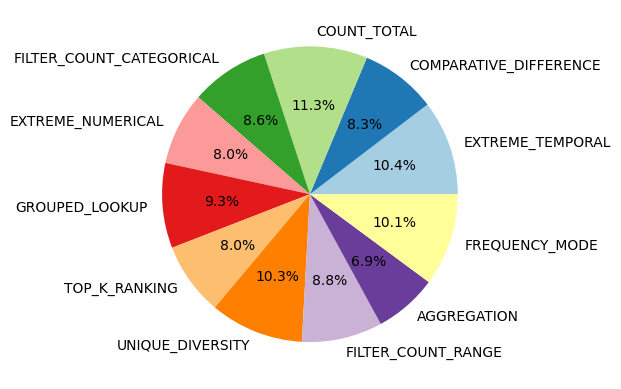

In [245]:
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector, QuestionGenerator

sanitizer = TableSanitizer(group_constructor.valid_tables)
sanitizer.process_tables()

selector = StrategySelector(sanitizer.sanitized_tables)
selector.get_strategies()

generator = QuestionGenerator(selector.updated_data, 
                              strategy_definitions=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
_ = await generator.generate_questions()

In [246]:
co = 0
for sample in generator.valid_results:
    if sample['Selected strategy'] == "AGGREGATION":
        co += 1
        print(f"Group name: {sample['Group name']}")
        print(f"Strategy: {sample['Selected strategy']}")
        print(f"Question: {sample['Question']}")
        print(f"Wikipedia page: {sample['Wiki link']}")
        display(pd.DataFrame(sample['Relevant table data']))
        display(pd.DataFrame(sample['Full table data']))
        print()
        print()
        if co > 15:
            break

Group name: Men's PSA World Rankings Players
Strategy: AGGREGATION
Question: What is the total number of points accumulated by all players in the Men's PSA World Rankings?
Wikipedia page: https://en.wikipedia.org/wiki/Squash_(sport)#Players,_records_and_rankings


,Player,Points
0,Mostafa Asal ( EGY ),2338
1,Diego Elías ( PER ),1631
2,Paul Coll ( NZL ),1153
3,Joel Makin ( WAL ),1096
4,Marwan Elshorbagy ( ENG ),847
5,Karim Gawad ( EGY ),811
6,Mohamed Elshorbagy ( ENG ),794
7,Youssef Soliman ( EGY ),616
8,Aly Abou Eleinen ( EGY ),580
9,Youssef Ibrahim ( EGY ),578


,Rank,Player,Points
0,1,Mostafa Asal ( EGY ),2338
1,2,Diego Elías ( PER ),1631
2,3,Paul Coll ( NZL ),1153
3,4,Joel Makin ( WAL ),1096
4,5,Marwan Elshorbagy ( ENG ),847
5,6,Karim Gawad ( EGY ),811
6,7,Mohamed Elshorbagy ( ENG ),794
7,8,Youssef Soliman ( EGY ),616
8,9,Aly Abou Eleinen ( EGY ),580
9,10,Youssef Ibrahim ( EGY ),578




Group name: Largest companies in Zambia
Strategy: AGGREGATION
Question: What is the total revenue generated by the largest companies in Zambia for the fiscal year 2021?
Wikipedia page: https://en.wikipedia.org/wiki/List_of_companies_of_Zambia#List_of_Largest_Firms


,Name,FY2021 Revenue (ZMW)
0,First Quantum Minerals Zambia (FQMZ),72828000000
1,Lumwana Mining Company Limited (LMC),16835000000
2,Mopani Copper Mines Plc,14927500000
3,Konkola Copper Mines Plc,11978400000
4,Copperbelt Energy Corporation,5985000000
5,Puma Energy Zambia,5841402000
6,Zambia Sugar,4989980000
7,Zambeef Products,4974351000
8,Zambia National Commercial Bank,3511658000
9,Zambian Breweries,3068959000


...

,Name,Revenue (USD millions)
0,Banco Santander,90531
1,Telefónica,57466
2,Repsol,53176
3,Banco Bilbao Vizcaya Argentaria,47608
4,ACS Group,43263
5,Iberdrola,41395
6,Inditex,30686
7,Naturgy,29123
8,Mapfre,27423


,Rank,Fortune 500 rank,Name,Industry,Revenue (USD millions),Profits (USD millions),Employees,Headquarters
0,1,85,Banco Santander,Banking,90531,9217,194015,Santander
1,2,176,Telefónica,Telecommunications,57466,3931,120138,Madrid
2,3,200,Repsol,Oil and gas,53176,2762,22735,Madrid
3,4,234,Banco Bilbao Vizcaya Argentaria,Banking,47608,6283,125627,Bilbao
4,5,272,ACS Group,Construction,43263,1080,195461,Madrid
5,6,292,Iberdrola,Electric utility,41395,3557,33216,Bilbao
6,7,406,Inditex,Retail,30686,4042,174386,Arteixo
7,8,430,Naturgy,Gas utility,29123,"−3,330",13945,Madrid
8,9,452,Mapfre,Insurance,27423,624,76913,Majadahonda




Group name: Hydroelectric power stations in Mali
Strategy: AGGREGATION
Question: What is the total capacity in megawatts of all hydroelectric power stations in Mali?
Wikipedia page: https://en.wikipedia.org/wiki/List_of_power_stations_in_Mali#Hydroelectric


,Hydroelectric station,Capacity (MW)
0,Félou Hydroelectric Plant,63.0
1,Gouina Hydroelectric Plant,140.0
2,Manantali Dam,200.0
3,Sélingué Dam,44.0
4,Sotuba Hydroelectric Plant,5.2


,Hydroelectric station,Community,Coordinates,Type,Capacity (MW),Completed,Name of reservoir,River
0,Félou Hydroelectric Plant,,14°21′04″N 11°20′53″W ﻿ / ﻿ 14.35111°N 11.3480...,Run of river,63.0,2014,,Senegal River
1,Gouina Hydroelectric Plant,,,,140.0,2017,,Senegal River
2,Manantali Dam,,13°11′44″N 10°25′44″W ﻿ / ﻿ 13.19556°N 10.4288...,Reservoir,200.0,2002,Manantali Reservoir,Bafing River
3,Sélingué Dam,,11°38′17″N 08°13′47″W ﻿ / ﻿ 11.63806°N 8.22972...,Reservoir,44.0,1982,Lake Sélingué,Sankarani River
4,Sotuba Hydroelectric Plant,Bamako,12°38′16″N 07°55′31″W ﻿ / ﻿ 12.63778°N 7.92528...,Run of river,5.2,1960,,Niger River
